<a href="https://colab.research.google.com/github/JPerezTx/f1-race-predictor/blob/main/f1_race_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install fastf1 scipy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 24.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [fastf1]


In [3]:
import os
import fastf1
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

os.makedirs("cache", exist_ok=True)
fastf1.Cache.enable_cache("cache")

YEAR = 2024
schedule = fastf1.get_event_schedule(YEAR, include_testing=False)

rows = []
for rnd in schedule["RoundNumber"]:
    s = fastf1.get_session(YEAR, int(rnd), "R")
    s.load(laps=False, telemetry=False, weather=False, messages=False)
    r = s.results[["Abbreviation", "GridPosition", "Position"]].copy()
    r["round"] = int(rnd)
    rows.append(r)

results = pd.concat(rows, ignore_index=True)
results = results.dropna(subset=["GridPosition", "Position"])
print(results.head())

/usr/local/lib/python3.13/dist-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "
core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.9.2]
INFO:fastf1.fastf1.core:Loading data for Bahrain Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
INFO:fastf1.fastf1.req:No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
INFO:fastf1.api:Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
INFO:fastf1.f1account:Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
DEBUG:fastf1.fastf1.req:Falling back to ht

  Abbreviation  GridPosition  Position  round
0          LEC           1.0       1.0      8
1          PIA           2.0       2.0      8
2          SAI           3.0       3.0      8
3          NOR           4.0       4.0      8
4          RUS           5.0       5.0      8


In [5]:
# Pit-lane starters show grid position 0; treat them as starting last
results.loc[results["GridPosition"] == 0, "GridPosition"] = 20

results = results.sort_values(["Abbreviation", "round"])
results["form"] = (
    results.groupby("Abbreviation")["Position"]
    .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
)
# First race has no history, so fall back to grid position
results["form"] = results["form"].fillna(results["GridPosition"])

In [6]:
def evaluate(w):
    out = []
    for rnd, g in results.groupby("round"):
        score = (1 - w) * g["GridPosition"] + w * g["form"]
        pred = score.rank(method="first")
        corr = spearmanr(pred, g["Position"])[0]
        mae = (pred - g["Position"]).abs().mean()
        out.append((corr, mae))
    return pd.DataFrame(out, columns=["spearman", "mae"]).mean()

weights = [0, 0.2, 0.4, 0.6]
summary = pd.DataFrame({w: evaluate(w) for w in weights}).T
summary.index.name = "weight_on_form"
print(summary)

                spearman       mae
weight_on_form                    
0.0             0.706678  2.988235
0.2             0.724635  2.917647
0.4             0.740734  2.882353
0.6             0.735869  2.994118


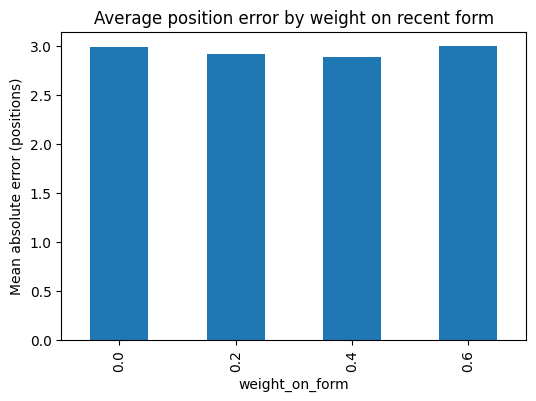

In [7]:
summary["mae"].plot(kind="bar", figsize=(6, 4))
plt.title("Average position error by weight on recent form")
plt.ylabel("Mean absolute error (positions)")
plt.show()